# 4. Near-duplicates, LSH neighbour features and their evaluation (MinHash / LSH, WELFake)

WELFake merges four source datasets, and the same story often appears more than once: re-posted by another site, with
a new headline, an extra intro or a "share this" footer. Exact duplicates were already dropped in cleaning (8,264 rows),
but **near-duplicates** remain. If one copy lands in `train` and another in `test`, a model can score well by
recognizing the text instead of judging it.

MinHash/LSH has two roles in the project:

1. **Leakage control.** Near-duplicate groups (two tiers: MinHash near-copies and embedding paraphrases) define
   `split_grouped`, where every group stays in one partition.
2. **Features.** For every article, a train-only LSH index finds similar training articles; three numbers summarize
   their labels and go into the final classifier.

The MinHash/LSH code is implemented from scratch with NumPy and the standard library (`fake_news.similarity`):

| Step | What | Module |
|---|---|---|
| 1. Shingles | article → set of word shingles, hashed with `crc32` | `shingles.py` |
| 2. MinHash | set → 128 minima of random hash functions (estimates Jaccard) | `minhash.py` |
| 3. LSH | banding → candidate pairs, without comparing all 2 billion pairs | `lsh.py` |
| 4. Verify | exact Jaccard of every candidate pair | `groups.py` |
| 5. Group | union-find over the kept pairs → `doc_id → group_id` | `groups.py` |
| 6. Second tier | embedding neighbours (cosine) + containment rule, merged with union-find | `paraphrases.py` |
| 7. Features | train-only LSH index (2-word shingles, 64 × 2) → neighbour features | `lsh_features.py` |
| 8. Evaluation | LSH vs exact Jaccard, leakage audit | `lsh_eval.py` |

Scripts (in this order): `find_near_duplicates.py` (MinHash tier, ~1 min), `find_paraphrases.py --write` (second
tier), `build_grouped_split.py`, `build_lsh_features.py --regime random grouped` (~10 min per regime),
`evaluate_lsh.py` (~35 min the first time, cached afterwards). This notebook reads their outputs; sections 1-5
recompute the MinHash tier because that is fast.

**Only train and val are used. No test article is scored anywhere in this notebook.**

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fake_news import config
from fake_news.data import load_clean, load_splits
from fake_news.data.split import check_split
from fake_news.similarity import lsh, lsh_eval, minhash, plots
from fake_news.similarity import lsh_features as lf
from fake_news.similarity import near_duplicates as nd
from fake_news.similarity import paraphrases as pp
from fake_news.similarity.shingles import jaccard, shingle_ids, words

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
plots.use_style()
REPORT = nd.REPORT_DIR   # reports/minhash/

clean = load_clean(columns=["title", "content", "n_words"])
labels = clean.set_index("doc_id")["is_fake"]
report = json.loads((REPORT / "near_dup_summary.json").read_text())  # written by the script
THRESHOLD = report["settings"]["threshold"]
print(f"{len(clean):,} cleaned articles, {labels.mean():.1%} fake; MinHash threshold used: {THRESHOLD}")

62,525 cleaned articles, 44.4% fake; MinHash threshold used: 0.7


## 1. Shingles and Jaccard similarity

An article becomes the **set** of its 3-word shingles. Words are runs of letters and digits, so punctuation does not
matter. Each shingle is stored as its `crc32` hash, a 32-bit integer. Python's `hash()` is not used because it is
randomized per process: the same text would get different ids in every run.

The similarity of two articles is the **Jaccard similarity** of their shingle sets, $J(A,B) = |A \cap B| / |A \cup B|$.
Three-word shingles are short enough that an edited copy still shares most of them, and long enough that unrelated
articles share few (common phrases like "the united states" are rare compared with the whole set).

In [2]:
text = "trump signs new tax bill today"
w = words(text)
print([" ".join(w[i:i + 3]) for i in range(len(w) - 2)])
print(shingle_ids(text))

a, b = np.array([1, 2, 3]), np.array([2, 3, 4])
print("J =", jaccard(a, b))

['trump signs new', 'signs new tax', 'new tax bill', 'tax bill today']
[   2934821  580416443 1969217837 3374127782]
J = 0.5


Articles with fewer than 5 distinct shingles (texts of up to about 6 words) get **no signature** and always stay
singletons. They are kept in the data on purpose (cleaning decision G7), but with so few shingles two unrelated
teasers can reach a high Jaccard similarity by chance.

In [3]:
t0 = time.perf_counter()
table = nd.compute_signatures(clean)   # reads data/interim/minhash_signatures.npz if it is up to date
print(f"{'cache' if table.from_cache else 'computed'} in {time.perf_counter() - t0:.1f} s; "
      f"report run took {report['seconds']}")
print(f"signatures: {table.signatures.shape}; {table.n_shingles.sum():,} shingles in total")
print(f"articles without signature (< {nd.MIN_SHINGLES} shingles): {len(table.short_doc_ids)}")
table.n_shingles.describe().round(0).to_frame("distinct shingles per article").T

cache in 0.0 s; report run took {'load': 3.69, 'minhash': 0.03, 'lsh': 2.14, 'verify': 1.7, 'recall': 4.87, 'groups': 0.11}
signatures: (62446, 128); 34,040,779 shingles in total
articles without signature (< 5 shingles): 79


,count,mean,std,min,25%,50%,75%,max
distinct shingles per article,62525.0,544.0,586.0,0.0,244.0,409.0,675.0,23017.0


## 2. MinHash: estimating Jaccard from 128 numbers

For a random hash function $h$, the shingle with the smallest hash in $A \cup B$ is equally likely to be any of its
elements, and $\min h(A) = \min h(B)$ exactly when that shingle lies in $A \cap B$. So
$P[\min h(A) = \min h(B)] = J(A,B)$. With 128 hash functions $h_i(x) = (a_i x + b_i) \bmod P$, where $P = 2^{31}-1$
and $a_i, b_i$ are drawn with `config.SEED`, the share of agreeing positions estimates $J$ with a standard error of
$\sqrt{J(1-J)/128} \le 0.044$. Every article becomes 128 integers, whatever its length.

Overflow: shingle ids are reduced mod $P$ first, so $a x + b < 2^{62} + 2^{31}$ fits in `int64`.

3,954 candidate pairs, verified in 3.0 s


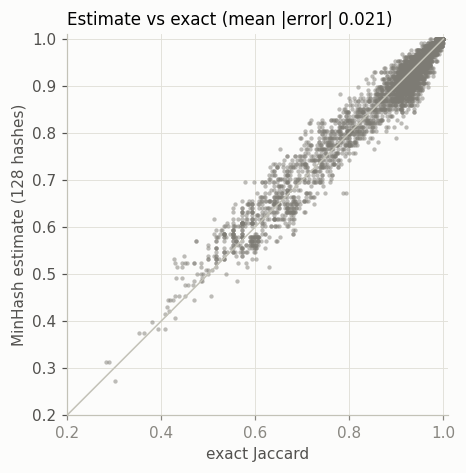

In [4]:
t0 = time.perf_counter()
cands = nd.verify_candidates(nd.find_candidates(table), clean)   # LSH candidates + exact Jaccard (section 3)
print(f"{len(cands):,} candidate pairs, verified in {time.perf_counter() - t0:.1f} s")
fig = plots.estimate_vs_exact(cands)
plots.save(fig, "minhash_estimate_vs_exact")
plt.show()

The estimates scatter around the diagonal as expected. Exact verification still matters near the threshold:
an error of ±0.04 decides whether a pair at 0.72 is kept or not.

## 3. LSH: finding candidate pairs without comparing every pair

All pairs would be 1.9 billion comparisons. **Banding** cuts each signature into 16 bands of 8 values. In each band,
articles with the same 8 values share a bucket, and two articles that share a bucket in at least one band become a
*candidate pair*. A pair with similarity $s$ becomes a candidate with probability $1 - (1 - s^8)^{16}$, an S-curve
around $(1/16)^{1/8} \approx 0.71$:

In [5]:
s = np.array([0.5, 0.6, 0.7, 0.8, 0.9])
pd.DataFrame({"s": s, "P(candidate)": lsh.candidate_probability(s).round(3)}).set_index("s").T

s,0.5,0.6,0.7,0.8,0.9
P(candidate),0.061,0.237,0.613,0.947,1.0


In [6]:
sizes = lsh.bucket_sizes(table.signatures)
n_sig = len(table.doc_ids)
print(f"{len(cands):,} candidate pairs out of {n_sig * (n_sig - 1) // 2:,} possible "
      f"({len(cands) / (n_sig * (n_sig - 1) / 2):.1e} of all pairs)")
print(f"{len(sizes):,} buckets with 2+ articles; largest bucket: {sizes.max()} articles")

3,954 candidate pairs out of 1,949,720,235 possible (2.0e-06 of all pairs)
10,908 buckets with 2+ articles; largest bucket: 38 articles


**How many pairs does 16 × 8 miss?** To check, we band the same signatures more loosely (32 bands × 4 rows,
threshold ≈ 0.42) and verify those candidates as well. The share of the loose banding's pairs that 16 × 8 also finds
estimates our recall. Per similarity bin it should follow the S-curve; above a threshold it is the share of
near-duplicates we actually catch.

In [7]:
loose = nd.verify_candidates(nd.find_candidates(table, bands=32, rows=4), clean)
recall = nd.lsh_recall(cands, loose)
recall

,threshold,reference_pairs,found,recall
0,0.50,6258,3908,0.6245
1,0.60,4430,3687,0.8323
2,0.70,3472,3354,0.9660
3,0.75,3208,3187,0.9935
4,0.80,2997,2991,0.9980
5,0.85,2799,2799,1.0000
6,0.90,2457,2457,1.0000


## 4. Choosing the threshold

Exact Jaccard of all candidate pairs (top) and the LSH S-curve with the measured recall per bin (bottom).
The measured points follow the theoretical curve, which confirms the banding works as intended:

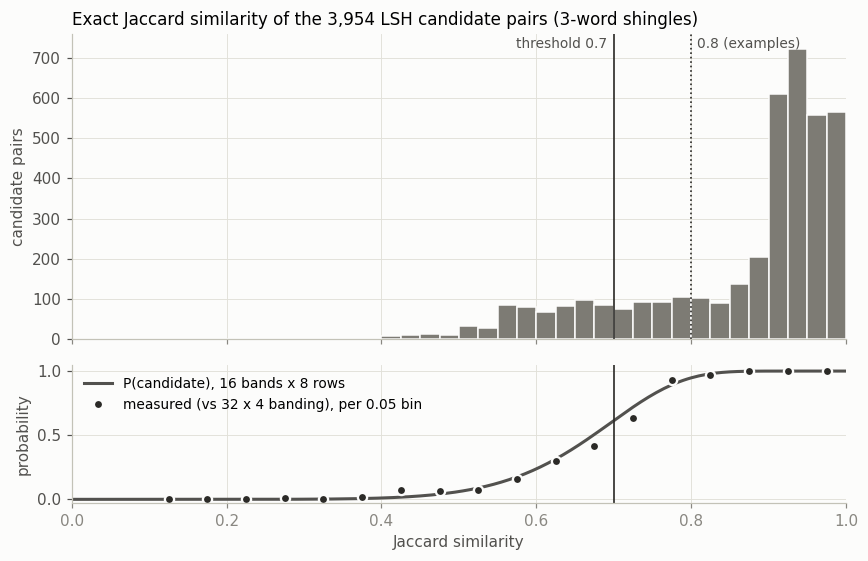

In [8]:
fig = plots.jaccard_histogram(cands, threshold=THRESHOLD, reference=0.8, recall=nd.binned_recall(cands, loose))
plots.save(fig, "minhash_candidate_jaccard")
plt.show()

Most candidates are almost identical (J > 0.9). Below that the histogram is flat down to about 0.55, and below
0.55 it drops, partly because LSH rarely proposes such pairs. Label disagreement does not help to choose: in every bin
fewer than 2% of the pairs mix a fake and a real article.

The pairs just above and just below 0.8 show what the threshold decides. `only_in_a` and `only_in_b` are the words that
differ (from `difflib`):

In [9]:
examples = pd.read_csv(nd.REPORT_DIR / "threshold_examples.csv")
examples[["side", "jaccard", "doc_a", "doc_b", "is_fake_a", "is_fake_b", "n_words_a", "n_words_b",
          "title_a", "title_b", "only_in_a", "only_in_b"]]

,side,jaccard,doc_a,doc_b,is_fake_a,is_fake_b,n_words_a,n_words_b,title_a,title_b,only_in_a,only_in_b
0,above,0.801,41249,53052,1,1,618,642,WikiLeaks CONFIRMS Hillary Sold Weapons to ISIS Then Drops Another BOMBSHELL!,WikiLeaks: Confirms Hillary Sold Weapons To ISIS,then drops another bombshell | theres | hes | hes | obamas | via the duran here is the...,there s | he s | via alternativenews | he s | scroll down for video below | obama s | ...
1,above,0.800,14856,60545,1,1,2472,2442,"Obama, Clinton and Putin Play on the Same Team-America Has Been Betrayed","Obama, Clinton and Putin Play on the Same Team-America Has Been Betrayed",donâ tmt | americaâ tms | annaâ tms | isnâ tmt | russiaâ tms | ofâ russiaâ tms | â | â...,obama clinton and putin play on the same team america has been betrayed previous | don...
2,above,0.800,145,45064,1,1,1347,1474,The Bolton Threat to Trump's Middle East Policy,Will Trump Resist War Hawks on Iran?,the | threat to trump s | policy written by gareth porter post election | us | us | pe...,will trump resist war hawks on iran will trump resist war hawks on iran november 15 20...
3,above,0.800,11152,13345,1,1,49,45,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,4 | and 3 2016,3
4,above,0.800,12536,24849,1,1,68,72,Somali Home Invasions!,Cancer Patients and Priests Targeted by Googles,somali home invasions | âš,cancer patients and priests targeted by googles
5,above,0.800,12536,42459,1,1,68,72,Somali Home Invasions!,Why Did Four Googles Kill This White?,somali home invasions | âš,why did four googles kill this white
6,above,0.800,20976,32842,1,1,52,59,Boiler Room EP #78,Boiler Room EP #77 - The Venom of Divide and Rule,78,77 the venom of divide and rule
7,above,0.800,37654,43557,1,1,36,40,Newly Approved GM Potatoes Have Potential to Silence Human Genes,Newly Approved GM Potatoes Have Potential to Silence Human Genes,NaN,late | resist potato blight
8,above,0.800,41766,42022,1,1,78,73,Welcome to the 'Islamic State of Germany',PAT CONDELL: America's last chance...,welcome to the islamic state of germany | contact top posts,pat condell america s last chance
9,above,0.800,44352,50521,1,1,45,48,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,4,3 | and 3 2016


Pairs on **both** sides of 0.8 are the same article with a different headline, intro or footer, or with encoding
differences ("donâ tmt" vs "don t"). Pairs between 0.7 and 0.8 look the same. So 0.8 would split real copies across
partitions. Group statistics for several thresholds:

In [10]:
comparison = nd.threshold_table(clean["doc_id"], cands, labels)
comparison.join(recall.set_index("threshold")["recall"].rename("lsh_recall"))

,verified_pairs,n_articles,groups_2plus,articles_in_groups_2plus,share_articles_in_groups,largest_group,mixed_label_groups,articles_in_mixed_groups,lsh_recall
threshold,,,,,,,,,
0.50,3908,62525,1080,2711,0.0434,42,14,30,0.6245
0.60,3687,62525,1052,2627,0.0420,42,13,28,0.8323
0.70,3354,62525,1002,2445,0.0391,40,13,28,0.9660
0.75,3187,62525,952,2308,0.0369,40,12,26,0.9935
0.80,2991,62525,882,2126,0.0340,40,8,18,0.9980
0.85,2799,62525,806,1924,0.0308,40,7,16,1.0000
0.90,2457,62525,695,1650,0.0264,40,7,16,1.0000


**Proposed threshold: 0.7.**

- Pairs between 0.7 and 0.8 are mostly real copies. Of the 363 such pairs only 23 involve a text shorter than 50
  words, where chance matches are possible.
- For the grouped split, a missed duplicate (a leak between train and test) costs more than a false group (two
  unrelated articles that just share a partition). That argues for the lower end.
- Below 0.7 the 16 × 8 banding stops being reliable: it finds 97% of pairs with J ≥ 0.7, but only 83% of those with
  J ≥ 0.6. A lower threshold would need a different banding (e.g. 32 × 4).
- Going from 0.8 to 0.7 adds 120 groups and about 320 articles. The largest group stays at 40.

## 5. Near-duplicate groups

Pairs with $J \ge$ threshold are edges of a graph, and the groups are its connected components, found with
**union-find**. If A ~ B and B ~ C, all three are one group even when A and C differ more: otherwise B would link
train and test. The group id is the smallest `doc_id` in the group.

In [11]:
groups = nd.load_minhash_groups()             # data/processed/near_dup_groups_minhash.csv (written by the script)
assert groups.equals(nd.make_groups(clean["doc_id"], cands, THRESHOLD))   # same as recomputing here
summary = nd.group_summary(groups, labels)
gt = nd.group_table(groups, labels)
{k: v for k, v in summary.items() if k != "group_size_counts"}

{'n_articles': 62525,
 'groups_2plus': 1002,
 'articles_in_groups_2plus': 2445,
 'share_articles_in_groups': 0.0391,
 'largest_group': 40,
 'mixed_label_groups': 13,
 'articles_in_mixed_groups': 28}

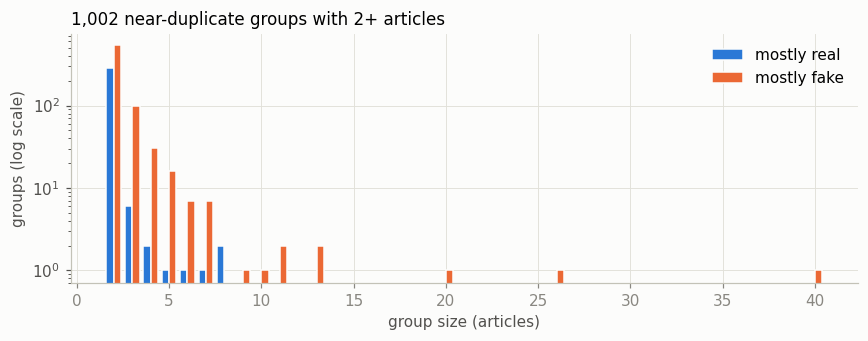

In [12]:
fig = plots.group_sizes(gt)
plots.save(fig, "minhash_group_sizes")
plt.show()

Most groups are pairs. The largest groups are worth a look: what links them?

In [13]:
for gid in gt.index[:4]:
    print(f"group {gid}: {gt.at[gid, 'size']} articles, {gt.at[gid, 'n_fake']} fake")
    display(nd.describe_group(groups, gid, clean, n=4))

group 216: 40 articles, 40 fake


,is_fake,n_words,title,content_start
doc_id,,,,
216,1,327,"Syrian War Report - October 28, 2016: Militants Make Do-Or-Die Attem …","syrian war report - october 28, 2016: militants make do-or-die attempt to break aleppo..."
5694,1,319,Moveable Feast Cafe 2016/11/14 ... Open Thread,moveable feast cafe 2016/11/14 ... open thread. it s preferable that you choose a name...
5959,1,324,New Comment Features have been Added,new comment features have been added. be the first to comment! it s preferable that yo...
6097,1,324,How my family Stopped a Chronic MRSA Infection When Conventional Med …,how my family stopped a chronic mrsa infection when conventional medicine failed. it s...


group 1352: 26 articles, 26 fake


,is_fake,n_words,title,content_start
doc_id,,,,
1352,1,215,Testimonial - 'I can focus better' from Kate,testimonial - i can focus better from kate. click here to learn more about alexandra s...
3234,1,215,"Core Wounds, Soul Family Reunions, and Time Glitches","core wounds, soul family reunions, and time glitches. click here to learn more about a..."
3456,1,218,"Benjamin Fulford Full Update in Spanish & English: October 24, 2016","benjamin fulford full update in spanish & english: october 24, 2016. click here to lea..."
6250,1,212,Alex Collier on Angels 2016-10-22,alex collier on angels 2016-10-22. click here to learn more about alexandra s personal...


group 114: 20 articles, 20 fake


,is_fake,n_words,title,content_start
doc_id,,,,
114,1,4237,CNN: One voter can make a difference by voting repeatedly,cnn: one voter can make a difference by voting repeatedly. channel list following hurr...
153,1,4342,The Glorious New PC NFL Starts Next Monday!,"the glorious new pc nfl starts next monday! afraid of ""dangerous"" trump presidency, pr..."
3480,1,4234,Yogagate: Clinton's instructor received classified emails,yogagate: clinton s instructor received classified emails. channel list following hurr...
5907,1,4370,Obama to pardon HAMILTON cast,"obama to pardon hamilton cast. in hillary s america, email server scrubs you obama tra..."


group 4949: 13 articles, 13 fake


,is_fake,n_words,title,content_start
doc_id,,,,
4949,1,254,Trump's Twitter Access Revoked - The Onion,trump s twitter access revoked - the onion. nation puts 2016 election into perspective...
5247,1,257,5 Things To Know About The Electoral College - The Onion,5 things to know about the electoral college - the onion. nation puts 2016 election in...
7117,1,259,Penn State Fined $2.4 Million For Handling Of Sandusky Case - The On …,penn state fined $2.4 million for handling of sandusky case - the onion. nation puts 2...
7513,1,254,Starbucks 'Unity' Cup Draws Criticism - The Onion,starbucks unity cup draws criticism - the onion. nation puts 2016 election into perspe...


The largest groups are not re-posted stories but **scraping residue**. Their titles all differ, but the body is
the same page element: a comment form ("it s preferable that you choose a name so it becomes clear who said what…",
40 articles), a promo footer ("click here to learn more about alexandra s personalized essences", 26), a site sidebar
("channel list…", 20), or The Onion's "more headlines" box (13). All of them are fake. Keeping each one in a single
partition is exactly right: otherwise a model learns "this boilerplate means fake". They also show that some
widget text survived cleaning.

**Mixed-label groups** (the same text labeled fake and real):

In [14]:
mixed = gt[gt["mixed"]]
print(f"{len(mixed)} mixed groups, {mixed['size'].sum()} articles")
for gid in mixed.index[:4]:
    display(nd.describe_group(groups, gid, clean, n=4))

13 mixed groups, 28 articles


,is_fake,n_words,title,content_start
doc_id,,,,
24117,1,1356,BOMBSHELL: 2006 Audio Emerges Of Hillary Clinton Proposing Rigging P …,bombshell: 2006 audio emerges of hillary clinton proposing rigging palestine election....
41177,1,1251,2006 Audio Emerges of Hillary Clinton Proposing Rigging Palestine El …,2006 audio emerges of hillary clinton proposing rigging palestine election. 2006 audio...
46438,0,1238,2006 Audio Emerges of Hillary Clinton Proposing Rigging Palestine El …,2006 audio emerges of hillary clinton proposing rigging palestine election. on septemb...
66003,1,1419,BOMBSHELL: 2006 Audio Emerges of Crooked Hillary Clinton Proposing R …,bombshell: 2006 audio emerges of crooked hillary clinton proposing rigging palestine e...


,is_fake,n_words,title,content_start
doc_id,,,,
43593,0,568,"In hats and t-shirts, Trump fans rally in Jerusalem's Old City","in hats and t-shirts, trump fans rally in jerusalem s old city. on a rooftop overlooki..."
52074,1,569,"In hats and t-shirts, Trump fans rally in Jerusalem's Old City","in hats and t-shirts, trump fans rally in jerusalem s old city. reuters on a rooftop o..."


,is_fake,n_words,title,content_start
doc_id,,,,
51254,0,567,Syrian political opposition says hopes Clinton wins U.S. presidency,syrian political opposition says hopes clinton wins u.s. presidency. syria s political...
67092,1,705,Assad's Opposition in Syria Favors Clinton Win for President,assad s opposition in syria favors clinton win for president. assad s opposition in sy...


,is_fake,n_words,title,content_start
doc_id,,,,
30393,0,824,U.S. militia girds for trouble as presidential election nears,u.s. militia girds for trouble as presidential election nears. down a georgia country ...
47943,1,840,U.S. militia girds for trouble as presidential election nears,u.s. militia girds for trouble as presidential election nears. u.s. militia girds for ...


Most mixed groups are **Reuters articles re-posted by sites labeled fake**, nearly word for word (J ≈ 0.95-0.99).
WELFake labels by source, so the same text carries both labels. No model can get both right, which puts a small
ceiling on accuracy. Keeping each group in one partition at least stops the conflict from crossing the split.

## 6. Second tier: paraphrases and truncated copies (embeddings)

MinHash with J ≥ 0.7 only finds copies with the same wording. Two other kinds of duplicates escape it:

- **Truncated copies.** One text contains the other but is much longer. Jaccard divides by the *union*, which the
  extra length inflates, so a fully contained text can score far below 0.7.
- **Paraphrases.** The same story in other words: few shared shingles.

The second tier uses the MiniLM sentence embeddings of the shared pipeline (L2-normalized, so cosine = dot product).
For every article the exact top-10 cosine neighbours are computed (`paraphrases.embedding_topk`, ~1 min), and a pair
is linked if

- cosine ≥ **0.92**, or
- 0.90 ≤ cosine < 0.92 **and** 3-word shingle containment ≥ **0.7** (the *containment rule*).

Containment is the share of the *shorter* text's shingles that also occur in the other text. Both tiers' links go into
one union-find. Results from `scripts/find_paraphrases.py --write`:

In [15]:
tt = json.loads((REPORT / "two_tier_summary.json").read_text())
print("links:", tt["links_by_rule"], "| MinHash groups enlarged or joined:", tt["minhash_groups_enlarged_or_joined"])
pd.read_csv(REPORT / "embedding_threshold_comparison.csv").set_index("threshold")

links: {'embedding': 2274, 'containment': 243} | MinHash groups enlarged or joined: 88


,embedding_pairs,new_links,groups_2plus,articles_in_groups,articles_added,largest_group,mixed_label_groups
threshold,,,,,,,
0.88,5266,3429,2453,6449,4004,65,182
0.90,3271,1583,1827,4500,2055,40,80
0.92,2274,745,1402,3412,967,40,44
0.93,1946,529,1279,3111,666,40,32
0.94,1667,370,1182,2892,447,40,25
0.95,1434,262,1120,2751,306,40,24
0.96,1197,169,1086,2656,211,40,20
0.97,950,102,1052,2574,129,40,17


**Why 0.92 and not lower: topic chaining.** Below about 0.92 most embedding pairs are *different* articles about the
same running news topic, and union-find chains a whole topic into one group. Mixed fake/real groups grow fast (80 at
0.90, 44 at 0.92 without the containment rule) because fake and real outlets cover the same events. At 0.90 one group
held 35 different Reuters articles on the Hariri / Lebanon crisis. At 0.92 a 15-article Hariri group remains: 0.92
reduces chaining but does not remove it. This group, linked by embeddings only:

In [16]:
final = nd.load_groups()                                    # data/processed/near_dup_groups.csv (two tiers)
tiers = pd.read_csv(nd.GROUPS_CSV).set_index("doc_id")["tier"]
largest = pd.read_csv(REPORT / "two_tier_largest_groups.csv")
display(largest.head(8))
hariri = largest.loc[largest["example_title"].str.contains("Hariri"), "group_id"].iloc[0]
nd.describe_group(final, hariri, clean, n=8)

,group_id,size,n_fake,mixed,tier,example_title
0,216,40,40,False,minhash,"Syrian War Report - October 28, 2016: Militants Make Do-Or-Die Attempt to Break Aleppo..."
1,1352,26,26,False,minhash,Testimonial - 'I can focus better' from Kate
2,114,20,20,False,minhash,CNN: One voter can make a difference by voting repeatedly
3,8295,15,0,False,embedding,Lebanon's Hariri to visit Egypt on Tuesday: Hariri's office
4,3540,13,13,False,minhash,"BULGARIA: Nearly l,000 Muslim freeloaders rebel over ""bad food and delays in giving th..."
5,4949,13,13,False,minhash,Trump's Twitter Access Revoked - The Onion
6,21495,12,0,False,both+containment,Factbox: Trump fills top jobs for his administration
7,3141,11,11,False,minhash,Get Ready For Civil Unrest: Survey Finds That Most Americans Are Concerned About Elect...


,is_fake,n_words,title,content_start
doc_id,,,,
8295,0,297,Lebanon's Hariri to visit Egypt on Tuesday: Hariri's office,"lebanon s hariri to visit egypt on tuesday: hariri s office. saad al-hariri, who annou..."
8999,0,371,Lebanon's Aoun holds talks on Hariri government,lebanon s aoun holds talks on hariri government. president michel aoun held talks on m...
17319,0,762,Hariri to return to Lebanon in next two days,hariri to return to lebanon in next two days. saad al-hariri will return to lebanon fr...
18633,0,597,"Lebanon's Hariri rescinds resignation, drawing line under crisis","lebanon s hariri rescinds resignation, drawing line under crisis. lebanese prime minis..."
21636,0,365,Lebanon's Hariri holds talks with Egypt President Sisi in Cairo,lebanon s hariri holds talks with egypt president sisi in cairo. lebanon s saad al-har...
22445,0,1018,"Lebanon PM Hariri resigns, assails Iran and Hezbollah","lebanon pm hariri resigns, assails iran and hezbollah. lebanon s prime minister saad a..."
24137,0,541,Lebanon's president welcomes Hariri's plans to return,"lebanon s president welcomes hariri s plans to return. lebanese president michel aoun,..."
35341,0,665,Lebanon's Hariri visits UAE as home crisis escalates,lebanon s hariri visits uae as home crisis escalates. lebanon s outgoing prime ministe...


**Truncated copies are their own category.** Every embedding link that MinHash did not have is described by its
containment and length ratio (`paraphrases.link_type`, descriptive only). Truncated copies (containment ≥ 0.8, length
ratio ≥ 1.5) are copies that MinHash misses *because of length*, not paraphrases:

In [17]:
print("embedding links by type (cosine >= 0.92):", tt["embedding_links_by_type"])
print("links added by the containment rule, by type:", tt["containment_rule_links_by_type"])
pd.read_csv(REPORT / "truncated_copy_examples.csv")[["cosine", "jaccard", "containment", "n_words_a", "n_words_b",
                                                     "is_fake_a", "is_fake_b", "text_a"]].head(6)

embedding links by type (cosine >= 0.92): {'minhash': 1688, 'truncated_copy': 189, 'edited_copy': 127, 'partial_overlap': 346, 'paraphrase': 167}
links added by the containment rule, by type: {'minhash': 159, 'truncated_copy': 33, 'edited_copy': 26, 'partial_overlap': 25, 'paraphrase': 0}


,cosine,jaccard,containment,n_words_a,n_words_b,is_fake_a,is_fake_b,text_a
0,0.974,0.394,0.970,412,163,0,0,u.s. lawmakers seek temporary extension to internet spying program. republican leaders...
1,0.973,0.327,0.839,623,261,0,0,saudi-led coalition opens yemen border crossing; aid agencies warn of famine. the saud...
2,1.000,0.133,1.000,1662,225,1,1,the pathologization of dissent. photo by jamelle bouie | cc by 2.0 according to the ma...
3,0.992,0.232,0.987,2032,491,1,1,the israeli trumpess. what will donald trump do if he loses the elections in a week an...
4,0.984,0.268,0.921,799,229,0,1,clinton s charity confirms qatar s $1 million gift while she was at state dept. the cl...


**The containment rule.** Moving from 0.90 to 0.92 also dropped 33 truncated-copy and 26 edited-copy links whose cosine
was just below 0.92. Topic neighbours share almost no wording, so the containment test keeps them out. The rule
recovers all 59 copy links, adds 25 partial overlaps (containment 0.70-0.79), lets no paraphrase through and brings no
chain back (the largest groups are unchanged). Final groups by tier:

In [18]:
by_tier = pd.DataFrame(tt["by_tier"]).T
by_tier.loc["final (all tiers)"] = [tt["final"]["groups_2plus"], tt["final"]["articles"], tt["final"]["mixed_label_groups"]]
by_tier.loc["MinHash tier alone"] = [tt["minhash_tier_alone"]["groups_2plus"], tt["minhash_tier_alone"]["articles"],
                                     tt["minhash_tier_alone"]["mixed_label_groups"]]
print(f"final: {tt['final']['articles']:,} articles in groups = {tt['final']['share_of_all_articles']:.1%} of all")
by_tier.astype(int)

final: 3,494 articles in groups = 5.6% of all


,groups,articles,mixed
both,51,204,3
both+containment,27,133,0
embedding,404,883,31
embedding+containment,37,79,2
minhash,914,2195,10
final (all tiers),1433,3494,46
MinHash tier alone,1002,2445,13


`tier` tells which links formed a group: `minhash`, `embedding` or `both`. The suffix `+containment` means at least one
link between different MinHash groups came from the containment rule. One false link comes from a shared author-bio
header (`NOTE_cleaning_residue.md`, section 4).

## 7. The grouped split and the leakage it removes

`split_grouped` (in `splits.csv`, built by `scripts/build_grouped_split.py`) keeps every final group in one partition:
70/15/15, stratified by the group's majority label. `split_random` is unchanged. `check_split` raises if a group
crosses partitions:

In [19]:
splits = load_splits().set_index("doc_id")
display(check_split(splits["split_grouped"], labels=labels, groups=final))

def with_group_member_in_train(split, groups):
    # val articles that have another member of their group in train
    train_groups = groups[split.reindex(groups.index) == "train"].value_counts()
    val = split.index[split == "val"]
    return pd.Series(groups.loc[val].map(train_groups).fillna(0).to_numpy() > 0, index=val)

for name, g in (("final groups", final), ("MinHash groups only", nd.load_minhash_groups())):
    leak = with_group_member_in_train(splits["split_random"], g)
    y = labels.loc[leak.index]
    print(f"random split, {name}: {leak.sum()} val articles ({leak.mean():.1%}) have a group member in train "
          f"(fake {leak[y == 1].sum()} = {leak[y == 1].mean():.1%}, real {leak[y == 0].sum()} = {leak[y == 0].mean():.1%})")
print("grouped split:", with_group_member_in_train(splits["split_grouped"], final).sum(), "val articles")

,n,fraction,fake_rate
split_grouped,,,
train,43766,0.70,0.444
val,9380,0.15,0.444
test,9379,0.15,0.444


random split, final groups: 394 val articles (4.2%) have a group member in train (fake 252 = 6.0%, real 142 = 2.7%)
random split, MinHash groups only: 277 val articles (3.0%) have a group member in train (fake 202 = 4.8%, real 75 = 1.4%)


grouped split: 0 val articles


Under the random split 4.2% of val articles have a copy or paraphrase in train, and fake articles twice as often as
real ones (fake stories get re-posted more). Under the grouped split there are none, by construction.

## 8. LSH neighbour features

For every article (train, val, test), a train-only LSH index finds similar **training** articles, and three numbers
summarize them (`lsh_features.py`, built by `scripts/build_lsh_features.py`):

| Feature | Definition | No neighbour |
|---|---|---|
| `fake_neighbor_share` | $\sum_i J_i \cdot \text{fake}_i / \sum_i J_i$ over neighbours with $J \ge 0.1$ | train fake rate (0.444) |
| `max_jaccard` | similarity of the closest neighbour | 0 |
| `neighbor_count` | number of neighbours with $J \ge 0.1$ | 0 |

Design (chosen with the neighbour voting analysis on random val, `LSH_FEATURES_DESIGN.md`): **2-word** shingles, which
raised coverage from 12.8% (3-word, even with exact search) to 18.6%; **64 bands × 2 rows**, which proposes pairs down
to J ≈ 0.1; exact Jaccard of every candidate; a **prefilter** that skips candidates whose signatures agree in fewer
than 5 of 128 positions (a pair at J = 0.1 agrees in Binomial(128, 0.1) positions, mean 12.8, and falls below 5 with
probability < 1%).

**Exclusion rule.** Training articles are in the index, so a training article would find itself. Its features must
look like a val article's: under the random split it ignores itself (`exclude="self"`); under the grouped split it also
ignores its whole near-duplicate group (`exclude="group"`), because a grouped val article never has a group member in
train. The sanity report checks that train and val look alike:

In [20]:
feats_g = lf.load_lsh_features("grouped")      # checks the split column against splits.csv
feats_r = lf.load_lsh_features("random")
for regime in ("random", "grouped"):
    print(regime)
    display(pd.read_csv(REPORT / f"lsh_features_sanity_{regime}.csv").set_index("split").round(3))

random


,n,share_no_neighbor,mean_max_jaccard,median_max_jaccard,mean_max_jaccard_if_any,mean_neighbor_count,share_fake_if_fake,share_fake_if_real,share_fake_if_fake_with_nb,share_fake_if_real_with_nb,with_group_member_in_train
split,,,,,,,,,,,
train,43767,0.806,0.064,0.0,0.333,0.548,0.525,0.357,0.932,0.040,1382
val,9379,0.814,0.062,0.0,0.334,0.523,0.524,0.360,0.945,0.038,277
test,9379,0.808,0.062,0.0,0.324,0.519,0.521,0.358,0.923,0.047,270


grouped


,n,share_no_neighbor,mean_max_jaccard,median_max_jaccard,mean_max_jaccard_if_any,mean_neighbor_count,share_fake_if_fake,share_fake_if_real,share_fake_if_fake_with_nb,share_fake_if_real_with_nb,with_group_member_in_train
split,,,,,,,,,,,
train,43766,0.835,0.035,0.0,0.212,0.441,0.501,0.363,0.913,0.040,2445
val,9380,0.840,0.034,0.0,0.210,0.462,0.499,0.366,0.912,0.041,0
test,9379,0.839,0.034,0.0,0.211,0.408,0.496,0.365,0.897,0.044,0


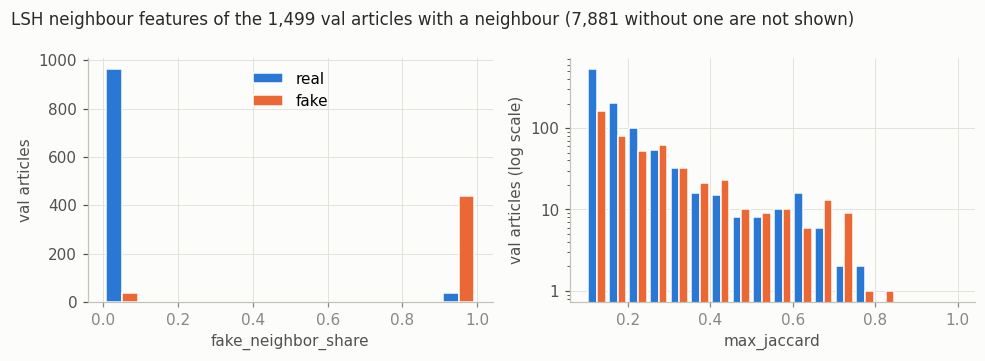

In [21]:
fig = plots.feature_distributions(feats_g, labels, "val")
plots.save(fig, "lsh_features_val_grouped")
plt.show()

About 84% of articles have no neighbour and get the fallback, so `fake_neighbor_share` must never be used alone: the
model needs `max_jaccard` and `neighbor_count` to know whether the share is evidence or the default. For the articles
that do have neighbours, the share separates the classes well (fake articles: mean 0.91, real: 0.04 on grouped val).
`neighbor_count` is skewed (use `log1p`), and all three should be standardized with a scaler fit on train.

## 9. Evaluation

### 9.1 Retrieval quality: LSH against exact Jaccard

LSH only proposes candidate pairs. To see what it misses we need the exact Jaccard of **every** pair, which LSH exists
to avoid. `lsh_eval.PostingLists` computes it with an inverted index: all shingles sorted once, so for one article
`np.bincount` over the slices of its shingles gives its intersection with every other article at once.

- **Sample:** 3,000 random articles (seed 42), all 4,498,500 pairs, 3-word shingles.
- **Full data:** all 62,446 articles with a signature, every pair with exact J ≥ 0.2 (10,691 pairs out of 1.95 billion).

The sample holds very few near-duplicate pairs (a pair is in it only if *both* articles are sampled, probability
≈ (3,000 / 62,525)² ≈ 0.2%), so its recall estimates have wide 95% intervals. The full data gives the precise numbers.
Recall at J ≥ t = share of the true pairs with J ≥ t that are candidates; false-positive rate at t = share of the
candidates whose true J is below t (they are verified away, so they cost time, not quality).

In [22]:
ev = json.loads((REPORT / "lsh_eval_summary.json").read_text())
print("sample: pairs by exact Jaccard:", ev["sample"]["pairs_by_jaccard"])
ret = pd.read_csv(REPORT / "lsh_eval_retrieval.csv")
ret["recall (95% CI)"] = [f"{r:.3f} ({lo:.2f}-{hi:.2f}) n={n}" for r, lo, hi, n in
                          zip(ret["recall"], ret["recall_ci_low"], ret["recall_ci_high"], ret["true_pairs"])]
display(ret.pivot(index=["data", "banding"], columns="threshold", values="recall (95% CI)"))
ret.pivot_table(index=["data", "banding", "candidates", "candidates_per_article"], columns="threshold",
                values="false_positive_rate").round(3)

sample: pairs by exact Jaccard: {'<0.1': 4498454, '0.1-0.2': 16, '0.2-0.3': 7, '0.3-0.5': 3, '0.5-0.7': 14, '>=0.7': 6}


threshold                            0.5                       0.6                       0.7                       0.8                       0.9
data   banding                                                                                                                                  
full   16x8     0.607 (0.60-0.62) n=6435  0.832 (0.82-0.84) n=4434  0.966 (0.96-0.97) n=3472  0.998 (1.00-1.00) n=2997  1.000 (1.00-1.00) n=2457
       32x4     0.973 (0.97-0.98) n=6435  0.999 (1.00-1.00) n=4434  1.000 (1.00-1.00) n=3472  1.000 (1.00-1.00) n=2997  1.000 (1.00-1.00) n=2457
       64x2     1.000 (1.00-1.00) n=6435  1.000 (1.00-1.00) n=4434  1.000 (1.00-1.00) n=3472  1.000 (1.00-1.00) n=2997  1.000 (1.00-1.00) n=2457
sample 16x8       0.350 (0.18-0.57) n=20    0.438 (0.23-0.67) n=16     0.667 (0.30-0.90) n=6     0.667 (0.21-0.94) n=3     1.000 (0.34-1.00) n=2
       32x4       0.950 (0.76-0.99) n=20    1.000 (0.81-1.00) n=16     1.000 (0.61-1.00) n=6     1.000 (0.44-1.00) n=3     1.000 (0.34-1.00) n=2
       64x2       1.000 (0.84-1.00) n=20    1.000 (0.81-1.00) n=16     1.000 (0.61-1.00) n=6     1.000 (0.44-1.00) n=3     1.000 (0.34-1.00) n=2

threshold                                           0.5    0.6    0.7    0.8    0.9
data   banding candidates candidates_per_article                                   
full   16x8    3954       0.1266                  0.012  0.068  0.152  0.244  0.379
       32x4    7621       0.2441                  0.179  0.419  0.544  0.607  0.678
       64x2    184352     5.9044                  0.965  0.976  0.981  0.984  0.987
sample 16x8    7          0.0047                  0.000  0.000  0.429  0.714  0.714
       32x4    19         0.0127                  0.000  0.158  0.684  0.842  0.895
       64x2    437        0.2913                  0.954  0.963  0.986  0.993  0.995

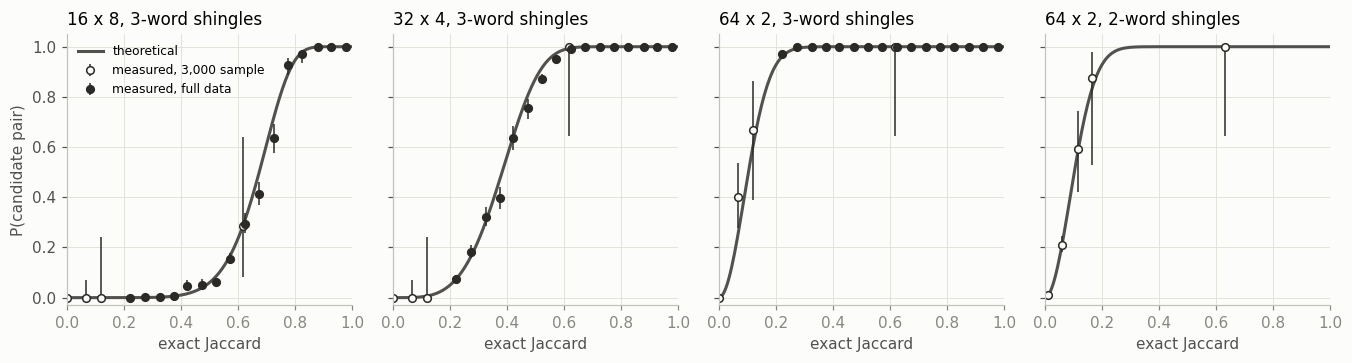

In [23]:
fig = plots.s_curves(pd.read_csv(REPORT / "lsh_eval_s_curve.csv"))
plots.save(fig, "lsh_eval_s_curves")
plt.show()

The measured candidate rates follow the theoretical S-curve $1 - (1 - s^r)^b$ for every banding (each point is the
mean prediction for the pairs in a 0.05 bin, plotted at their mean J). For the groups (16 × 8, threshold 0.7):

- recall is 0.966 at J ≥ 0.7, 0.998 at J ≥ 0.8 and 1.000 at J ≥ 0.9; at 0.6 it would only be 0.83;
- 15% of the 3,954 candidates are below 0.7 and are dropped by the exact check;
- the old estimate (recall against a looser 32 × 4 banding, section 3) gave the same 0.966, because 32 × 4 itself
  misses nothing above 0.6.

The 118 pairs with J ≥ 0.7 that 16 × 8 missed (J 0.70-0.85) are mostly caught anyway: 78 end up in the same final group
through other links. **21 pairs cross partitions of `split_grouped`**, a small residual leak:

In [24]:
print(ev["full"]["missed_by_16x8_at_0.7"])
missed = pd.read_csv(REPORT / "lsh_eval_missed_pairs.csv")
missed[missed["across_split_grouped"]].head(10)

{'pairs': 118, 'same_minhash_group': 43, 'same_final_group': 78, 'across_split_grouped': 21}


,doc_a,doc_b,jaccard,same_minhash_group,same_final_group,partition_a,partition_b,across_split_grouped
0,62,4912,0.7256,False,False,test,train,True
6,2566,51224,0.7000,False,False,val,train,True
7,2583,36828,0.7701,False,False,train,val,True
8,2746,23402,0.7019,False,False,test,train,True
9,2746,43499,0.7228,False,False,test,train,True
10,2932,16775,0.7201,False,False,train,test,True
12,3653,29510,0.7273,False,False,val,train,True
13,3653,58891,0.7273,False,False,val,test,True
16,4000,45204,0.7179,False,False,train,val,True
21,5859,8997,0.7031,False,False,test,train,True


**Runtime.** Signatures dominate the LSH cost (26 s for 62,446 articles); banding and verification take 1-14 s. The
exact search with the inverted index takes 3 minutes. That is already a clever brute force: comparing pair by pair
(`np.intersect1d`, ~40 µs per pair) would take about 22 hours. On the 3,000 sample all methods take 1-2 s; the
advantage of LSH grows with the data size, because exact search still touches every article that shares any shingle.

In [25]:
pd.read_csv(REPORT / "lsh_eval_runtime.csv").round(2)

,data,method,articles,signatures_s,banding_s,verify_s,total_s,pairs_checked
0,sample,LSH 16x8,3000,1.35,0.04,0.00,1.39,7
1,sample,LSH 32x4,3000,1.35,0.06,0.00,1.41,19
2,sample,LSH 64x2,3000,1.35,0.14,0.01,1.51,437
3,sample,"brute force, posting lists (measured)",3000,NaN,NaN,NaN,1.88,4498500
4,sample,"brute force, pair by pair (extrapolated)",3000,NaN,NaN,NaN,168.51,4498500
5,full,LSH 16x8,62446,25.62,1.17,0.26,27.04,3954
6,full,LSH 32x4,62446,25.62,2.62,0.35,28.58,7621
7,full,LSH 64x2,62446,25.62,6.48,6.92,39.01,184352
8,full,"brute force, posting lists (measured)",62446,NaN,NaN,NaN,182.08,1949720235
9,full,"brute force, pair by pair (extrapolated)",62446,NaN,NaN,NaN,79353.47,1949720235


### 9.2 The feature index (2-word shingles, 64 × 2, prefilter, J ≥ 0.1)

The same check for the index behind the features. On the sample every article is in the index and ignores itself;
on val (grouped split) the queries are the 9,380 val articles against the train-only index, exactly as the features are
built. Recall is counted over (query, training article) pairs.

In [26]:
fi = pd.read_csv(REPORT / "lsh_eval_feature_index.csv")
fi[["data", "method", "ms_per_article", "candidates_per_article", "threshold", "true_pairs", "found", "recall",
    "recall_ci_low", "articles_with_neighbor", "articles_with_neighbor_exact"]].round(3)

,data,method,ms_per_article,candidates_per_article,threshold,true_pairs,found,recall,recall_ci_low,articles_with_neighbor,articles_with_neighbor_exact
0,sample,lsh_prefilter,0.645,34.999,0.1,150.0,122.0,0.813,0.743,0.033,0.039
1,sample,lsh_prefilter,0.645,34.999,0.2,70.0,70.0,1.000,0.948,0.033,0.039
2,sample,lsh_prefilter,0.645,34.999,0.3,54.0,54.0,1.000,0.934,0.033,0.039
3,sample,lsh_prefilter,0.645,34.999,0.5,40.0,40.0,1.000,0.912,0.033,0.039
4,sample,lsh_prefilter,0.645,34.999,0.7,12.0,12.0,1.000,0.758,0.033,0.039
5,sample,lsh_no_prefilter,1.456,34.999,0.1,150.0,122.0,0.813,0.743,0.033,0.039
6,sample,lsh_no_prefilter,1.456,34.999,0.2,70.0,70.0,1.000,0.948,0.033,0.039
7,sample,lsh_no_prefilter,1.456,34.999,0.3,54.0,54.0,1.000,0.934,0.033,0.039
8,sample,lsh_no_prefilter,1.456,34.999,0.5,40.0,40.0,1.000,0.912,0.033,0.039
9,sample,lsh_no_prefilter,1.456,34.999,0.7,12.0,12.0,1.000,0.758,0.033,0.039


- **Recall is 1.000 from J ≥ 0.3** and 0.989 at J ≥ 0.2, but **0.76 at 0.1 ≤ J**: the 64 × 2 S-curve only reaches
  P(candidate) = 0.47 at J = 0.1 and 0.77 at 0.15. So the features miss part of the weakest neighbours: on val 16.0%
  of articles get a neighbour, against 19.9% with exact search.
- The prefilter loses nothing (same recall with and without it) and halves the time.
- **At this data size the exact inverted-index search is faster than LSH** for 2-word shingles (7.3 vs 9.6 ms per val
  article): 2-word shingles are short and common, so LSH produces ~490 candidates per article that all need checking.
  LSH is kept because it is the method of the course and scales better; the feature values are the ones LSH gives.

### 9.3 Leakage audit (grouped split)

`split_grouped` removes the near-duplicate *groups*. How close can a val article still be to a training article? From
exact search (2-word Jaccard of the closest training article) and from the features (LSH):

In [27]:
pd.read_csv(REPORT / "leakage_audit_counts.csv").round(3)

,regime,source,threshold,val_articles,share_of_val,fake,share_of_fake_val,real,share_of_real_val
0,grouped,exact search,0.3,250,0.027,135,0.032,115,0.022
1,grouped,exact search,0.5,93,0.010,49,0.012,44,0.008
2,grouped,LSH features,0.3,250,0.027,135,0.032,115,0.022
3,grouped,LSH features,0.5,93,0.010,49,0.012,44,0.008
4,random,LSH features,0.3,564,0.060,365,0.088,199,0.038
5,random,LSH features,0.5,400,0.043,284,0.068,116,0.022


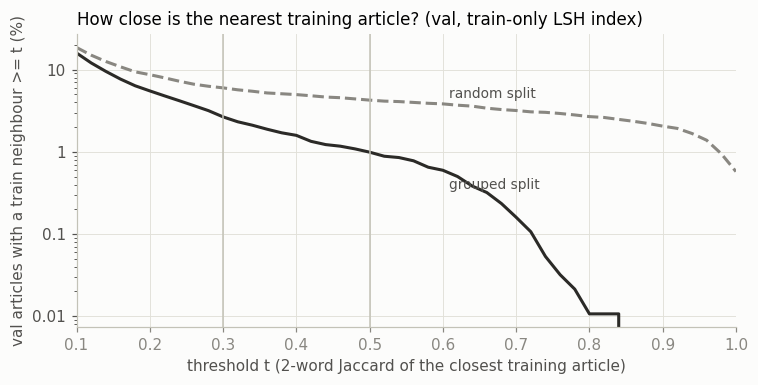

In [28]:
val_g = feats_g[feats_g["split"] == "val"]
val_r = feats_r[feats_r["split"] == "val"]
grid = np.round(np.arange(0.1, 1.0001, 0.02), 2)
curves = pd.DataFrame({"threshold": grid, "grouped": lsh_eval.share_above(val_g["max_jaccard"], grid),
                       "random": lsh_eval.share_above(val_r["max_jaccard"], grid)})
fig = plots.leak_share_curves(curves)
plots.save(fig, "leakage_max_jaccard")
plt.show()

LSH and exact search agree exactly at both thresholds (250 val articles at J ≥ 0.3, 93 at J ≥ 0.5), so the audit does
not depend on what LSH misses. Under the random split 400 val articles (4.3%) have a train neighbour at J ≥ 0.5; under
the grouped split 93 (1.0%). What are those 93 pairs?

In [29]:
pairs = pd.read_csv(REPORT / "leakage_audit_pairs.csv")
print(ev["leakage"]["leak_pairs_ge_0.5"])
display(pairs["kind"].value_counts())
pairs[["kind", "jaccard_2w", "jaccard_3w", "containment_3w", "cosine", "is_fake_val", "is_fake_train",
       "n_words_val", "n_words_train", "title_val", "title_train"]].head(12)

{'n': 93, 'same_label': 0.956989247311828, 'containment3_ge_0.7': 0.9139784946236559, 'median_jaccard_3w': 0.5926, 'median_cosine': 0.6776000261306763, 'by_kind': {'shared template text (cosine < 0.8)': 40, 'short text (< 50 words)': 31, 'same story (cosine >= 0.8)': 22}}


kind
shared template text (cosine < 0.8)    40
short text (< 50 words)                31
same story (cosine >= 0.8)             22
Name: count, dtype: int64

,kind,jaccard_2w,jaccard_3w,containment_3w,cosine,is_fake_val,is_fake_train,n_words_val,n_words_train,title_val,title_train
0,shared template text (cosine < 0.8),0.8412,0.8324,0.9798,0.6998,1,1,1382,1126,"BOOM! WATCH SEAN HANNITY Hit Back At Bogus Sexual Harassment Allegations: ""I can no lo...",BLOGGER Comes Clean About Hannity Sexual Harassment Claim...Hannity's Former Producer ...
1,same story (cosine >= 0.8),0.7801,0.7701,0.9456,0.8432,1,1,354,302,CLASSIC! PRESIDENT TRUMP Totally Rips CNN Reporter At Presser Over Comey Hearing [Video],WOW! SARA HUCKABEE-SANDERS Drops Mother Of All Verbal Bombs On Media Over Hypocrisy On...
2,same story (cosine >= 0.8),0.7643,0.7045,0.8392,0.8946,0,0,869,785,Contenders for key jobs in Trump administration,Factbox: Short list of potential picks for Trump administration
3,short text (< 50 words),0.7500,0.7083,0.8500,0.6861,0,0,21,22,How Cruz rescued Carson,Ben Carson vs. Ben Carson
4,short text (< 50 words),0.7451,0.6727,0.8409,0.6365,1,1,52,49,Boiler Room #105 - Quantum Swamp Chess,Boiler Room #103 - Smoking Gunz
5,short text (< 50 words),0.7391,0.7273,0.8889,0.6634,0,0,19,21,Gaming Obamacare,Clinton's Iowa dilemma
6,shared template text (cosine < 0.8),0.7374,0.6923,0.8471,0.5494,1,1,107,93,Chart Of The Day: The Bond Vigilantes Are Back! UST Yield Up 65bps Since Election,Chart Of The Day: The Ever-Widening Wage Gap
7,shared template text (cosine < 0.8),0.7351,0.7316,0.8627,0.3672,1,1,376,359,Calif. Proposition Requires Permit to Buy Bullets,UN Chief urges South Africa to reconsider quitting ICC
8,shared template text (cosine < 0.8),0.7273,0.6827,0.8353,0.6367,1,1,101,93,Chart Of The Day: Private Residential Construction Stalls-Out 40% Below Pre-Crisis Peak,Chart Of The Day: The Ever-Widening Wage Gap
9,shared template text (cosine < 0.8),0.7200,0.6762,0.8353,0.5598,1,1,107,93,"Chart Of The Day: Sorry, Mario! The Printing Press Can't Fix The Welfare State",Chart Of The Day: The Ever-Widening Wage Gap


Most of them are **not the same story**: the median embedding cosine is 0.68. They are different articles that share
template text (a site's "Chart of the Day" footer, The Onion's headline box, a common block of boilerplate) or very
short teasers (< 50 words) built from the same template. Only 22 look like the same story (cosine ≥ 0.8) with 3-word
Jaccard below 0.7. 96% of the pairs share their label, so this is a site/template signal rather than story leakage,
the same kind as the widget groups in section 5. The `kind` column is a descriptive heuristic only.

How does `fake_neighbor_share` perform on these articles and on the rest? (val, the feature as the model sees it;
ROC-AUC inside each subset, uncovered articles keep the fallback.)

In [30]:
pd.read_csv(REPORT / "leakage_audit_scores.csv").set_index(["regime", "subset"]).round(3)

n  share_of_val  fake_rate  coverage  f1_covered  accuracy_covered  roc_auc
regime  subset                                                                                                                   
grouped max J >= 0.5                                 93         0.010      0.527     1.000       0.960             0.957    0.954
        0.3 <= max J < 0.5                          157         0.017      0.548     1.000       0.912             0.904    0.901
        max J >= 0.3                                250         0.027      0.540     1.000       0.930             0.924    0.920
        rest: max J < 0.3                          9130         0.973      0.441     0.137       0.913             0.950    0.612
        rest with a neighbour: 0.1 <= max J < 0.3  1249         0.133      0.286     1.000       0.913             0.950    0.943
        all val                                    9380         1.000      0.444     0.160       0.918             0.946    0.629
random  max J >= 0.5                                400         0.043      0.710     1.000       0.989             0.985    0.986
        0.3 <= max J < 0.5                          164         0.018      0.494     1.000       0.963             0.963    0.969
        max J >= 0.3                                564         0.060      0.647     1.000       0.984             0.979    0.981
        rest: max J < 0.3                          8815         0.940      0.431     0.134       0.892             0.944    0.607
        rest with a neighbour: 0.1 <= max J < 0.3  1185         0.126      0.255     1.000       0.892             0.944    0.941
        all val                                    9379         1.000      0.444     0.186       0.942             0.955    0.652

- Under the grouped split, the 250 val articles with a train neighbour at J ≥ 0.3 (2.7% of val) are classified very
  well by the feature alone (F1 0.93, ROC-AUC 0.92). The remaining 97.3% give ROC-AUC 0.61, almost all of it from
  the 13.7% of them that have a weaker neighbour (0.1 ≤ J < 0.3), on which ROC-AUC is 0.94.
- Under the random split the J ≥ 0.5 subset is 4× larger (400 vs 93) and almost perfectly classified (F1 0.99), which
  is the near-duplicate leakage the grouped split removes.
- Overall the feature's signal on grouped val (ROC-AUC 0.629, coverage 16%) does not come from the remaining
  high-similarity pairs: without the val articles that have a neighbour at J ≥ 0.3, 13.7% of the rest still have a
  neighbour, and on those the feature reaches ROC-AUC 0.94.

## 10. Neighbour voting analysis (summary)

The neighbour vote on its own (`scripts/run_model_b.py`; an analysis tool, not a pipeline model): the
similarity-weighted fake share of the top k neighbours with J ≥ min_sim, or the train fake rate without neighbours.
Tuned on val only (k and min_sim); test never scored.

In [31]:
rows = {}
for regime in ("random", "grouped"):
    s = json.loads((config.PROJECT_ROOT / "reports" / "lsh_features" / f"voting_{regime}_summary.json").read_text())
    rows[regime] = {"k": s["k"], "min_sim": s["min_sim"], **s["val"]}
pd.DataFrame(rows).T

,k,min_sim,coverage,coverage_fake,coverage_real,f1_covered,accuracy_covered,f1_overall,accuracy_overall,roc_auc_overall
random,5.0,0.1,0.1865,0.1601,0.2076,0.9418,0.9554,0.2608,0.6186,0.6524
grouped,3.0,0.1,0.1598,0.1181,0.1931,0.9178,0.9460,0.1941,0.5998,0.6286


Moving from the random to the grouped split lowers coverage from 18.6% to 16.0% (mostly fake articles: 16.0% → 11.8%),
F1 on covered articles from 0.942 to 0.918 and ROC-AUC from 0.652 to 0.629. That difference is the measured effect of
near-duplicate leakage on this signal.

## 11. Outputs

| File | In git | Contents |
|---|---|---|
| `data/processed/near_dup_groups.csv` | yes | final groups: `doc_id, group_id, tier` (singletons: `group_id == doc_id`, tier `none`) |
| `data/processed/near_dup_groups_minhash.csv` | yes | MinHash tier only: `doc_id, group_id` |
| `data/processed/splits.csv` | yes | `split_random` (unchanged) and `split_grouped` |
| `data/processed/features/lsh__{random,grouped}.csv` | yes | `doc_id, split, fake_neighbor_share, max_jaccard, neighbor_count` |
| `data/interim/*.npz` | no | caches: signatures, embedding top-10, exact pairs of the evaluation |
| `reports/minhash/near_dup_summary.json`, `threshold_*.csv`, `largest_groups.csv` | yes | MinHash tier |
| `reports/minhash/two_tier_*`, `embedding_*.csv`, `*_examples.csv` | yes | second tier |
| `reports/minhash/lsh_features_*.{csv,json}` | yes | feature sanity reports |
| `reports/minhash/lsh_eval_*`, `leakage_audit_*.csv` | yes | evaluation (section 9) |
| `reports/lsh_features/voting_*` | yes | neighbour voting analysis |
| `reports/minhash/REPORT_NOTES.md`, `LSH_FEATURES_DESIGN.md`, `NOTE_cleaning_residue.md` | yes | notes |
| `reports/figures/minhash_*.png`, `lsh_*.png`, `leakage_*.png` | yes | figures of this notebook |

```python
from fake_news.similarity.near_duplicates import load_groups
from fake_news.similarity.lsh_features import load_lsh_features
groups = load_groups()                  # pd.Series doc_id -> group_id
feats = load_lsh_features("grouped")    # or "random"; checks the split against splits.csv
```